# 01 — Environment exploration: MountainCar-v0

**Goal of this notebook:** understand the environment *before* any learning, and produce the figures for the
**Environment** section of the report.

We answer four questions:
1. What do states, actions and rewards look like?
2. Where does the car start? (the article claims 0.521 — we check)
3. Can a random agent solve it? (baseline)
4. Can a simple hand-written rule solve it? (shows the momentum idea)

All figures are saved to `report/figures/`.

In [1]:
import os
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = os.path.join("..", "report", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print("Gymnasium version:", gym.__version__)

Gymnasium version: 1.4.0


## 1. Spaces, reward and limits

In [2]:
env = gym.make("MountainCar-v0")

info = pd.DataFrame({
    "Property": ["Position range", "Velocity range", "Actions", "Reward per step",
                 "Max steps per episode", "Reward threshold ('solved')"],
    "Value": [f"[{env.observation_space.low[0]:.2f}, {env.observation_space.high[0]:.2f}]",
              f"[{env.observation_space.low[1]:.2f}, {env.observation_space.high[1]:.2f}]",
              f"{env.action_space.n} (0 = push left, 1 = no push, 2 = push right)",
              "-1",
              env.spec.max_episode_steps,
              env.spec.reward_threshold],
})
info

,Property,Value
0,Position range,"[-1.20, 0.60]"
1,Velocity range,"[-0.07, 0.07]"
2,Actions,"3 (0 = push left, 1 = no push, 2 = push right)"
3,Reward per step,-1
4,Max steps per episode,200
5,Reward threshold ('solved'),-110.0


**Reading:** the state is continuous and 2-dimensional (position, velocity). Every step costs −1, so the
fewer steps the car needs, the higher the total reward. An episode lasts at most 200 steps, so **−200 means the
goal was never reached**. The task counts as solved when the average reward over 100 consecutive episodes is
**≥ −110**.

## 2. Where does the car start?

Start position: min = -0.600, max = -0.400
Start velocity: min = 0.000, max = 0.000


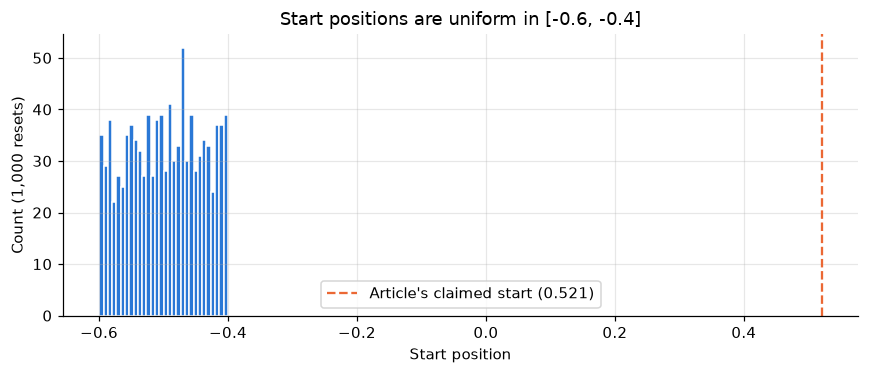

In [3]:
starts = np.array([env.reset(seed=i)[0] for i in range(1000)])
print(f"Start position: min = {starts[:, 0].min():.3f}, max = {starts[:, 0].max():.3f}")
print(f"Start velocity: min = {starts[:, 1].min():.3f}, max = {starts[:, 1].max():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(starts[:, 0], bins=30, color="#2a78d6", edgecolor="white")
ax.axvline(0.521, color="#eb6834", linestyle="--", label="Article's claimed start (0.521)")
ax.set_xlabel("Start position"); ax.set_ylabel("Count (1,000 resets)")
ax.set_title("Start positions are uniform in [-0.6, -0.4]")
ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "env_start_positions.png"), dpi=150); plt.show()

**Reading:** over 1,000 resets the car always starts between −0.6 and −0.4 with zero velocity, at the
bottom of the valley. The article's value of 0.521 is wrong: 0.5 is in fact the **goal** position.

## 3. The track: height = sin(3x)

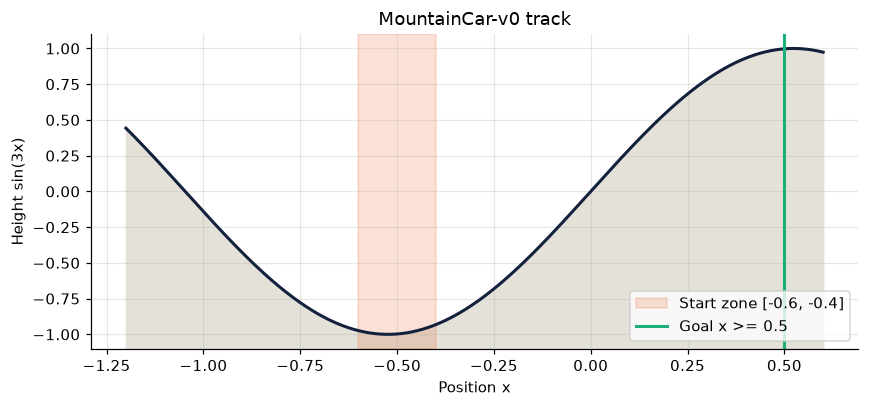

In [4]:
x = np.linspace(-1.2, 0.6, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(x, np.sin(3 * x), -1.1, color="#E3E1D8")
ax.plot(x, np.sin(3 * x), color="#14213D", lw=2)
ax.axvspan(-0.6, -0.4, color="#eb6834", alpha=0.2, label="Start zone [-0.6, -0.4]")
ax.axvline(0.5, color="#1baf7a", lw=2, label="Goal x >= 0.5")
ax.set_xlabel("Position x"); ax.set_ylabel("Height sin(3x)"); ax.set_ylim(-1.1, 1.1)
ax.set_title("MountainCar-v0 track"); ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "env_track.png"), dpi=150); plt.show()

## 4. Baselines: random agent vs. a hand-written rule

In [5]:
def run_policy(policy, episodes=100, seed_offset=0):
    """Run a policy; return a DataFrame with total reward, success and max position per episode,
    plus the (position, velocity) trajectory of the first episode."""
    rows, first_traj = [], None
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed_offset + ep)
        total, done, traj = 0, False, [obs]
        while not done:
            obs, r, term, trunc, _ = env.step(policy(obs))
            total += r
            traj.append(obs)
            done = term or trunc
        traj = np.array(traj)
        rows.append({"reward": total, "reached_goal": term, "max_position": traj[:, 0].max()})
        if first_traj is None:
            first_traj = traj
    return pd.DataFrame(rows), first_traj


rng = np.random.default_rng(0)
random_policy = lambda obs: int(rng.integers(3))
heuristic_policy = lambda obs: 2 if obs[1] >= 0 else 0   # push in the direction of motion

rand_df, rand_traj = run_policy(random_policy)
heur_df, heur_traj = run_policy(heuristic_policy)

summary = pd.DataFrame({
    "Agent": ["Random", "Heuristic (push with velocity)"],
    "Mean reward": [rand_df.reward.mean(), heur_df.reward.mean()],
    "Std": [rand_df.reward.std(), heur_df.reward.std()],
    "Success rate": [rand_df.reached_goal.mean(), heur_df.reached_goal.mean()],
    "Best max position": [rand_df.max_position.max(), heur_df.max_position.max()],
}).round(3)
summary

,Agent,Mean reward,Std,Success rate,Best max position
0,Random,-200.00,0.000,0.0,-0.218
1,Heuristic (push with velocity),-120.02,3.303,1.0,0.543


**Reading:** the random agent never reaches the flag: its pushes cancel out and the car stays near the
valley floor. The rule *"push in the direction you are already moving"* reaches the goal every time, because it
adds energy at each swing. It still averages worse than −110, so the threshold is demanding even for a
sensible strategy. **Q-learning must discover this swinging behaviour on its own, from a −1 reward only.**

## 5. Phase space: why swinging works

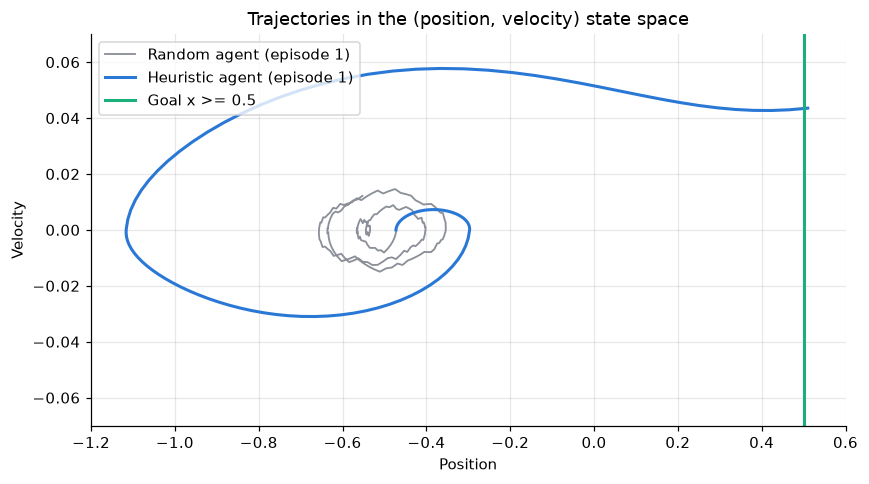

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rand_traj[:, 0], rand_traj[:, 1], color="#8A8F98", lw=1.2, label="Random agent (episode 1)")
ax.plot(heur_traj[:, 0], heur_traj[:, 1], color="#2a78d6", lw=2, label="Heuristic agent (episode 1)")
ax.axvline(0.5, color="#1baf7a", lw=2, label="Goal x >= 0.5")
ax.set_xlim(-1.2, 0.6); ax.set_ylim(-0.07, 0.07)
ax.set_xlabel("Position"); ax.set_ylabel("Velocity")
ax.set_title("Trajectories in the (position, velocity) state space")
ax.legend(loc="upper left"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "env_phase_space.png"), dpi=150); plt.show()

**Reading:** this is the 2D state space that our Q-table discretizes. The heuristic agent spirals outward:
each swing increases both the amplitude (position) and the speed until it crosses x = 0.5. The random agent
stays trapped in a small region around the start. A good Q-learning policy should produce a spiral like the
blue one.

---
### Summary for the report
- State: continuous 2D (position ∈ [−1.2, 0.6], velocity ∈ [−0.07, 0.07]); 3 discrete actions; −1 per step.
- Start: uniform in [−0.6, −0.4] — the article's 0.521 is incorrect.
- Random agent: −200 (never solves). Heuristic: reaches the goal 100% of the time but averages below −110.
- Figures saved: `env_start_positions.png`, `env_track.png`, `env_phase_space.png`.

In [7]:
env.close()